# 01 Сбор данных с Мосбиржи

Собираем реальные сделки с 2022 года для TQOB и TQCB. Сохраняем доходность,
модифицированную дюрацию и выпуклость. Пропущенные значения пока не заполняем.

Запускать ячейки по порядку. Папка `data` находится рядом с этим ноутбуком.
Сохранённые файлы используются повторно; для обновления истории включить `REFRESH_HISTORY`.
Текущий список бумаг не включает уже погашенные выпуски: это ограничение выборки.
Работа по ТЗ: целевые величины следующего этапа - DurationMod и Convexity,
модели обучаются отдельно. В этом ноутбуке сохраняем ход проверки расчётов.

## Подготовка

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display

BASE = "https://iss.moex.com/iss"
DATE_FROM = "2022-01-01"
DATE_TILL = pd.Timestamp.now(tz="Europe/Moscow").strftime("%Y-%m-%d")
REFRESH_HISTORY = False
REFRESH_REFERENCE = False

DATA = Path("notebooks/price_imputation/data") if Path("notebooks/price_imputation").exists() else Path("data")
for folder in [DATA, DATA / "history", DATA / "bondization", DATA / "calendar"]:
    folder.mkdir(parents=True, exist_ok=True)

## Запросы и повторное использование загруженных файлов

In [2]:
def get(path, params=None):
    params = {**(params or {}), "iss.meta": "off"}
    response = requests.get(f"{BASE}/{path}.json", params=params, timeout=30)
    response.raise_for_status()
    return response.json()

def to_df(data, name):
    return pd.DataFrame(data[name]["data"], columns=data[name]["columns"])

def get_history(secid, board):
    frames = []
    start = 0
    while True:
        data = get(f"history/engines/stock/markets/bonds/boards/{board}/securities/{secid}",
                   {"from": DATE_FROM, "till": DATE_TILL, "start": start})
        frame = to_df(data, "history")
        if frame.empty:
            break
        frames.append(frame)
        start += len(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def get_bondization(secid):
    data = get(f"securities/{secid}/bondization", {"limit": "unlimited"})
    return to_df(data, "coupons"), to_df(data, "amortizations"), to_df(data, "offers")

## Справочник облигаций

`FACEUNIT` - валюта номинала. Она может отличаться от валюты расчётов:
TQOB и TQCB рассчитываются в рублях даже для валютного номинала.
`COUPON_DETAILS` и `BONDTYPE` помогают определить тип купона.
Пустая сумма будущего купона сама по себе не означает флоатер.

In [3]:
bonds_file = DATA / "bonds.parquet"
if bonds_file.exists() and not REFRESH_REFERENCE:
    bonds = pd.read_parquet(bonds_file)
else:
    bonds = pd.concat([
        to_df(get(f"engines/stock/markets/bonds/boards/{board}/securities"), "securities")
        for board in ["TQOB", "TQCB"]
    ], ignore_index=True)

bonds = bonds.drop_duplicates("SECID").reset_index(drop=True)
bonds["currency"] = bonds["FACEUNIT"].replace({"SUR": "RUB"})
period = pd.to_numeric(bonds["COUPONPERIOD"], errors="coerce")
bonds["coupon_freq"] = (365 / period.where(period > 0)).round()
print(bonds["BOARDID"].value_counts())
print(bonds["currency"].value_counts())

BOARDID
TQCB    3027
TQOB      61
Name: count, dtype: int64
currency
RUB    2874
USD     138
CNY      58
EUR      16
CHF       2
Name: count, dtype: int64


## Скачиваем историю и выплаты

Каждый компонент проверяется отдельно. При прерванной загрузке недостающие файлы
докачиваются. Ошибки сохраняются в `data/download_errors.csv`.
`REFRESH_HISTORY=True` обновляет историю до `DATE_TILL`; графики и справочник
обновляются при `REFRESH_REFERENCE=True`.

In [4]:
download_errors = []
for i, row in bonds.iterrows():
    secid = row["SECID"]
    hist_file = DATA / "history" / f"{secid}.parquet"
    files = [DATA / "bondization" / f"{secid}_{part}.parquet"
             for part in ["coupons", "amorts", "offers"]]
    try:
        if not hist_file.exists() or REFRESH_HISTORY:
            get_history(secid, row["BOARDID"]).to_parquet(hist_file, index=False)
        if not all(file.exists() for file in files) or REFRESH_REFERENCE:
            for file, frame in zip(files, get_bondization(secid)):
                frame.to_parquet(file, index=False)
    except (requests.RequestException, ValueError, KeyError) as error:
        download_errors.append({"secid": secid, "error": str(error)})
    if (i + 1) % 500 == 0:
        print(i + 1, "/", len(bonds))

pd.DataFrame(download_errors, columns=["secid", "error"]).to_csv(DATA / "download_errors.csv", index=False)
print("Ошибок загрузки:", len(download_errors))

500 / 3088
1000 / 3088
1500 / 3088
2000 / 3088
2500 / 3088


3000 / 3088
Ошибок загрузки: 0


## Читаем локальные данные и приводим типы

In [5]:
history_cols = ["BOARDID", "TRADEDATE", "SECID", "NUMTRADES", "CLOSE", "YIELDCLOSE",
                "ACCINT", "FACEVALUE", "DURATION", "BUYBACKDATE", "OFFERDATE", "MATDATE",
                "COUPONPERCENT", "COUPONVALUE", "CALLOPTIONDATE", "PUTOPTIONDATE",
                "FACEUNIT", "BONDTYPE", "COUPON_DETAILS"]
frames = []
coupons, amorts, offers = {}, {}, {}
missing_files = []
for secid in bonds["SECID"]:
    hist_file = DATA / "history" / f"{secid}.parquet"
    files = [DATA / "bondization" / f"{secid}_{part}.parquet"
             for part in ["coupons", "amorts", "offers"]]
    if not hist_file.exists() or not all(file.exists() for file in files):
        missing_files.append(secid)
        continue
    frame = pd.read_parquet(hist_file)
    if frame.empty:
        continue
    frames.append(frame.reindex(columns=history_cols))
    coupons[secid], amorts[secid], offers[secid] = [pd.read_parquet(file) for file in files]

if not frames:
    raise ValueError("Нет истории: сначала выполните загрузку")
history_all = pd.concat(frames, ignore_index=True)
del frames
num_cols = ["NUMTRADES", "CLOSE", "YIELDCLOSE", "ACCINT", "FACEVALUE", "DURATION",
            "COUPONPERCENT", "COUPONVALUE"]
types_before = history_all[num_cols].dtypes.astype(str)
duplicates_before = int(history_all.duplicated(["SECID", "TRADEDATE"]).sum())
print("Дубликатов до обработки:", duplicates_before)
history_all[num_cols] = history_all[num_cols].apply(pd.to_numeric, errors="coerce")
for col in ["TRADEDATE", "BUYBACKDATE", "OFFERDATE", "MATDATE", "CALLOPTIONDATE", "PUTOPTIONDATE"]:
    history_all[col] = pd.to_datetime(history_all[col], format="%Y-%m-%d", errors="coerce")
history_all = history_all[history_all["TRADEDATE"].between(DATE_FROM, DATE_TILL)].copy()

keys = ["SECID", "TRADEDATE"]
if history_all.duplicated(keys).any():
    raise ValueError("Есть несколько строк на бумагу и день: проверьте TRADINGSESSION перед объединением")
history = history_all[history_all["NUMTRADES"] > 0].copy().reset_index(drop=True)
bad_yield = history["YIELDCLOSE"] <= -99
print("Строк с доходностью <= -99%:", int(bad_yield.sum()))
history.loc[bad_yield, "YIELDCLOSE"] = np.nan
history.loc[history["CLOSE"] <= 0, "CLOSE"] = np.nan

Дубликатов до обработки: 0


Строк с доходностью <= -99%: 240


In [6]:
print("История целиком:", history_all.shape, "со сделками:", history.shape)
print("Выпусков с недостающими файлами:", len(missing_files))

display(pd.DataFrame({"до обработки": types_before, "после": history_all[num_cols].dtypes.astype(str)}))

История целиком: (1562458, 19) со сделками: (917912, 19)
Выпусков с недостающими файлами: 0


,до обработки,после
NUMTRADES,int64,int64
CLOSE,object,float64
YIELDCLOSE,object,float64
ACCINT,object,float64
FACEVALUE,float64,float64
DURATION,object,float64
COUPONPERCENT,float64,float64
COUPONVALUE,float64,float64


## Тип купона

`floating` - в справочнике явно указан плавающий купон или привязка к ставке/индексу.
`fixed` - фиксированный купон, включая ещё не объявленные ставки после оферт.
`zero` - явно бескупонная (дисконтная) облигация.
`unknown` - данных недостаточно. Структурные бумаги отдельно исключаем из восстановления
цены по обычной облигационной формуле.

Для флоатеров `1 / coupon_freq` - учебное приближение дюрации, а не проверенный
расчёт чувствительности. Выпуклость 0 также является приближением.

In [7]:
def coupon_type(row):
    bondtype = str(row.get("BONDTYPE", "")).strip()
    details = str(row.get("COUPON_DETAILS", "")).strip()
    if row["SECID"].startswith("SU52"):
        return "fixed"
    if "плавающ" in bondtype.lower() or details in {
        "ИПЦ", "Индекс RUONIA", "Ключевая ставка", "Ставка RUONIA",
        "Срочная ставка RUONIA 3m", "Срочная ставка RUONIA 6m"
    }:
        return "floating"
    if "Фиксированный" in details or "фиксированным" in bondtype:
        return "fixed"
    if "Дисконтная" in bondtype:
        return "zero"
    c = coupons.get(row["SECID"])
    if c is not None and not c.empty and pd.to_numeric(c["value"], errors="coerce").notna().all():
        return "fixed"
    return "unknown"

bonds["coupon_type"] = bonds.apply(coupon_type, axis=1)
bond_info = bonds.set_index("SECID")
history["coupon_type"] = history["SECID"].map(bond_info["coupon_type"])
history["currency"] = history["SECID"].map(bond_info["currency"])
history["is_structured"] = history["SECID"].map(bond_info["BONDTYPE"]).eq("Структурная облигация")
print(bonds.groupby(["coupon_type", "currency"]).size())

coupon_type  currency
fixed        CHF            2
             CNY           58
             EUR           16
             RUB         1717
             USD          136
floating     RUB          629
unknown      RUB          526
             USD            2
zero         RUB            2
dtype: int64


## Дата расчётов и горизонт доходности

В TQOB/TQCB расчёты T+1 действовали уже с начала нашей выборки. Валюта номинала
не меняет режим расчётов этих двух досок. Календарь НКЦ хранит исключения к обычным
будням: `-` - для всех валют, `RUB` - для рубля. Используем поле `stock_market`.

Горизонт берём из исторического `BUYBACKDATE`, иначе из `MATDATE` той же строки.
Текущие оферты не переносим в прошлое. Не подменяем эти даты `CALLOPTIONDATE`:
дюрация к коллу публикуется отдельным показателем.

Источники: [календарь НКЦ](https://www.nationalclearingcentre.ru/rates/settleDates),
[режимы, изменённые в 2023 году](https://www.moex.com/a8482),
[изменение учёта оферт в 2025 году](https://www.moex.com/n91370).

Архив НКЦ за 2022 год неполон: для него используем будни и ставим
`settlement_calendar_exact=False`. Эти строки остаются в выгрузке, но пока
не входят в первый ML-эксперимент. Кеш календаря обновляется вместе со справочником.

In [8]:
calendar_frames = []
last_calendar_day = history["TRADEDATE"].max() + pd.Timedelta(days=31)
for year in range(history["TRADEDATE"].min().year, last_calendar_day.year + 1):
    file = DATA / "calendar" / f"ncc_{year}.parquet"
    if file.exists() and not REFRESH_REFERENCE:
        frame = pd.read_parquet(file)
    else:
        frame = to_df(get("rms/engines/currency/objects/settlementscalendar", {"year": year}),
                      "settlements_calendar")
        frame.to_parquet(file, index=False)
    if frame.empty:
        raise ValueError(f"Нет календаря НКЦ за {year}")
    calendar_frames.append(frame)
calendar = pd.concat(calendar_frames, ignore_index=True)
calendar["tradedate"] = pd.to_datetime(calendar["tradedate"])
calendar["stock_market"] = pd.to_numeric(calendar["stock_market"], errors="coerce")
calendar_days = pd.date_range(history["TRADEDATE"].min().normalize(), last_calendar_day)
settlement_allowed = pd.Series(calendar_days.day_of_week < 5, index=calendar_days)

for currency in ["-", "RUB"]:
    exceptions = calendar[(calendar["currencyid"] == currency) & calendar["stock_market"].notna()]
    exceptions = exceptions[exceptions["tradedate"].isin(calendar_days)]
    settlement_allowed.loc[exceptions["tradedate"]] = exceptions["stock_market"].eq(1).to_numpy()
settlement_days = settlement_allowed.index[settlement_allowed].to_numpy(dtype="datetime64[ns]")
if not history["BOARDID"].isin(["TQOB", "TQCB"]).all():
    raise ValueError("Для других досок нужно отдельно настроить валюту и цикл расчётов")
positions = np.searchsorted(settlement_days, history["TRADEDATE"].to_numpy(), side="right")
if (positions >= len(settlement_days)).any():
    raise ValueError("Календарь расчётов заканчивается раньше истории")
history["settle_date"] = settlement_days[positions]

covered_years = calendar.loc[calendar["currencyid"].isin(["-", "RUB"]), "tradedate"].dt.year.unique()
history["settlement_calendar_exact"] = history["TRADEDATE"].dt.year.isin(covered_years) & history["TRADEDATE"].dt.year.ge(2023)
print("Строк с приближённым календарём:", int((~history["settlement_calendar_exact"]).sum()))
history["yield_date"] = history["BUYBACKDATE"].combine_first(history["MATDATE"])
history["horizon_source"] = np.where(history["BUYBACKDATE"].notna(), "buyback", "maturity")
print(history[["TRADEDATE", "settle_date", "yield_date", "horizon_source"]].head())

Строк с приближённым календарём: 57980
   TRADEDATE settle_date yield_date horizon_source
0 2025-12-08  2025-12-09 2033-06-01       maturity
1 2025-12-09  2025-12-10 2033-06-01       maturity
2 2025-12-10  2025-12-11 2033-06-01       maturity
3 2025-12-11  2025-12-12 2033-06-01       maturity
4 2025-12-12  2025-12-15 2033-06-01       maturity


## Модифицированная дюрация Мосбиржи

При эффективной годовой доходности `y = YIELDCLOSE / 100` используем
`duration_mod = DURATION / 365 / (1 + y)`.
Нулевую биржевую дюрацию оставляем в исходной колонке, но не считаем надёжной
модифицированной дюрацией. Отдельно сохраняем происхождение значения.

In [9]:
valid_yield = history["YIELDCLOSE"].notna() & (history["YIELDCLOSE"] > -100)
history["duration_moex"] = (history["DURATION"].where(history["DURATION"] > 0)
                           / 365 / (1 + history["YIELDCLOSE"] / 100)).where(valid_yield)
history["duration_mod"] = history["duration_moex"]
history["duration_source"] = "moex"
is_float = history["coupon_type"].eq("floating")
freq = history["SECID"].map(bond_info["coupon_freq"])
history.loc[is_float, "duration_mod"] = 1 / freq[is_float].where(freq[is_float] > 0)
history.loc[is_float, "duration_source"] = "floating_approximation"

## Выплаты, дюрация и выпуклость

Грязная цена: `P(y) = sum(CF_i / pow(1 + y, t_i))`, `t_i` - годы от даты расчётов.
Производные этой же формулы дают:

- `D_mod = sum(t_i * PV_i) / (P * (1+y))`;
- `convexity = sum(t_i * (t_i+1) * PV_i) / (P * pow(1+y, 2))`.

Так не нужны три переоценки на каждую строку. Пропуск суммы выплаты не превращается
в ноль. В день оферты сохраняем купон и плановую амортизацию, а затем добавляем
возврат оставшегося номинала. При отсутствии известной цены выкупа принимаем 100%
и отмечаем это допущение.

Для ОФЗ-ИН используем текущий номинал и фиксированную ставку, без прогноза инфляции.
Выплаты из `value` берём в валюте номинала, а не из `value_rub`.

In [10]:
schedules = {}
for secid in coupons:
    c = coupons[secid].copy()
    a = amorts[secid].copy()
    cd = pd.to_datetime(c["coupondate"], format="%Y-%m-%d", errors="coerce")
    ad = pd.to_datetime(a["amortdate"], format="%Y-%m-%d", errors="coerce")
    cv = pd.to_numeric(c["value"], errors="coerce")
    av = pd.to_numeric(a["value"], errors="coerce")
    if secid.startswith("SU52"):
        starts = pd.to_datetime(c["startdate"], format="%Y-%m-%d", errors="coerce")
        rate = pd.to_numeric(c["valueprc"], errors="coerce")

        cv = rate / 100 * (cd - starts).dt.days / 365
        av = pd.to_numeric(a["valueprc"], errors="coerce") / 100
    dates = np.concatenate([cd.to_numpy(), ad.to_numpy()])
    amounts = np.concatenate([cv.to_numpy(dtype=float), av.to_numpy(dtype=float)])
    principal = np.concatenate([np.zeros(len(cd), dtype=bool), np.ones(len(ad), dtype=bool)])
    keep = ~pd.isna(dates)
    schedules[secid] = (dates[keep], amounts[keep], principal[keep])

In [11]:
def cashflow_arrays(secid, dates, facevalues, horizons, buyback):
    pay_dates, amounts, principal = schedules[secid]
    dates = np.asarray(dates, dtype="datetime64[ns]")
    horizons = np.asarray(horizons, dtype="datetime64[ns]")
    facevalues = np.asarray(facevalues, dtype=float)
    future = (pay_dates[None, :] > dates[:, None]) & (pay_dates[None, :] <= horizons[:, None])
    values = np.broadcast_to(amounts, future.shape).copy()
    if secid.startswith("SU52"):
        values *= facevalues[:, None]
    missing = (future & ~np.isfinite(values)).any(axis=1)
    principal_paid = np.where(future & principal[None, :], values, 0).sum(axis=1)
    remaining = facevalues - principal_paid

    redemption = np.maximum(remaining, 0)
    assumed_price = np.asarray(buyback, dtype=bool).copy()
    o = offers[secid]
    if not o.empty:
        od = pd.to_datetime(o["offerdate"], format="%Y-%m-%d", errors="coerce")
        prices = pd.to_numeric(o["price"], errors="coerce")
        for day, quote in zip(od, prices):
            if pd.notna(day) and pd.notna(quote) and quote > 0:
                matched = (horizons == day.to_datetime64()) & buyback
                redemption[matched] *= quote / 100
                assumed_price[matched] = False
    t = (pay_dates[None, :] - dates[:, None]) / np.timedelta64(1, "D") / 365
    end_t = (horizons - dates) / np.timedelta64(1, "D") / 365
    t = np.column_stack([np.where(future, t, 0), end_t])
    values = np.column_stack([np.where(future, values, 0), redemption])

    coupon_dates = pay_dates[~principal]
    period = pd.to_numeric(bond_info.loc[secid, "COUPONPERIOD"], errors="coerce")
    incomplete_coupons = np.zeros(len(dates), dtype=bool)
    if bond_info.loc[secid, "coupon_type"] == "fixed":
        if len(coupon_dates) == 0:
            incomplete_coupons[:] = True
        elif np.isfinite(period) and period > 0:
            incomplete_coupons = horizons > coupon_dates.max() + np.timedelta64(int(period + 7), "D")
    negative = (future & (values[:, :-1] < 0)).any(axis=1)
    invalid = missing | incomplete_coupons | negative | (remaining < -0.01) | ~np.isfinite(facevalues) | (facevalues <= 0)
    invalid |= pd.isna(horizons) | pd.isna(dates) | (horizons <= dates)
    return t, values, invalid, assumed_price

## Пересчитываем историю по каждой бумаге

In [12]:
for col in ["duration_calc", "convexity", "price_dirty_calc"]:
    history[col] = np.nan
history["calc_status"] = "unsupported_coupon_type"
history["offer_price_assumed"] = False
for secid, group in history.groupby("SECID", sort=False):
    idx = group.index
    coupon_kind = group["coupon_type"].iloc[0]
    if coupon_kind == "floating":
        history.loc[idx, "convexity"] = 0.0
        history.loc[idx, "calc_status"] = "floating_approximation"
        continue
    if coupon_kind not in ["fixed", "zero"] or group["is_structured"].any():
        continue
    t, amounts, invalid, assumed = cashflow_arrays(
        secid, group["settle_date"], group["FACEVALUE"], group["yield_date"],
        group["horizon_source"].eq("buyback").to_numpy())
    y = group["YIELDCLOSE"].to_numpy(dtype=float) / 100
    invalid |= ~np.isfinite(y) | (y <= -1)
    with np.errstate(invalid="ignore", divide="ignore", over="ignore"):
        pv = amounts / (1 + y[:, None]) ** t
        p = pv.sum(axis=1)
        duration = (t * pv).sum(axis=1) / p / (1 + y)
        convexity = (t * (t + 1) * pv).sum(axis=1) / p / (1 + y) ** 2
    invalid |= ~np.isfinite(p) | (p <= 0) | ~np.isfinite(duration) | ~np.isfinite(convexity)
    history.loc[idx, "duration_calc"] = np.where(invalid, np.nan, duration)
    history.loc[idx, "convexity"] = np.where(invalid, np.nan, convexity)
    history.loc[idx, "price_dirty_calc"] = np.where(invalid, np.nan, p)
    history.loc[idx, "offer_price_assumed"] = assumed
    status = np.where(invalid, "incomplete_schedule", "ok")
    status[~np.isfinite(y) | (y <= -1)] = "missing_yield"
    status[pd.isna(group["yield_date"]).to_numpy()] = "missing_horizon"
    history.loc[idx, "calc_status"] = status

print(history["calc_status"].value_counts())

calc_status
ok                         572975
floating_approximation     209985
unsupported_coupon_type     73264
missing_yield               40435
incomplete_schedule         13005
missing_horizon              8248
Name: count, dtype: int64


## Сравнение вариантов расчёта: пересчитываем четыре варианта на одних строках

Сравним варианты расчёта на одной выборке, чтобы отделить влияние даты расчётов,
исторических оферт и учёта возвращённого номинала.
Тип купона фиксируем по исправленной классификации, меняем только логику выплат:

1. Было: дата торгов, ближайшая оферта из сегодняшнего графика, возврат полного номинала.
2. Дата расчётов: те же выплаты, но отсчёт от T+1 по календарю НКЦ.
3. Историческая оферта: берём BUYBACKDATE из строки истории.
4. Стало: также сохраняем купон в день оферты и учитываем уже возвращённый номинал.

Пропущенные суммы в старом варианте суммировались как нули - сохраняем это поведение
для честного воспроизведения. Не отбираем только улучшившиеся строки.

In [13]:
def legacy_duration(secid, group, use_settlement=False, use_history=False):
    date = group["settle_date" if use_settlement else "TRADEDATE"].to_numpy()
    c, a = coupons[secid], amorts[secid]
    cd = pd.to_datetime(c["coupondate"], format="%Y-%m-%d", errors="coerce").to_numpy()
    ad = pd.to_datetime(a["amortdate"], format="%Y-%m-%d", errors="coerce").to_numpy()
    pay_dates = np.concatenate([cd, ad])
    amount = np.concatenate([pd.to_numeric(c["value"], errors="coerce"),
                             pd.to_numeric(a["value"], errors="coerce")])
    keep = ~pd.isna(pay_dates)
    pay_dates, amount = pay_dates[keep], amount[keep]
    values = np.broadcast_to(amount, (len(group), len(amount))).copy()
    if secid.startswith("SU52"):
        pay_dates = np.concatenate([cd, np.array([pd.to_datetime(bond_info.loc[secid, "MATDATE"])],
                                                dtype="datetime64[ns]")])
        coupon = group["FACEVALUE"].to_numpy() * float(bond_info.loc[secid, "COUPONPERCENT"]) / 100
        coupon /= float(bond_info.loc[secid, "coupon_freq"])
        values = np.column_stack([np.broadcast_to(coupon[:, None], (len(group), len(cd))), group["FACEVALUE"]])
    end = np.full(len(group), np.datetime64("NaT", "ns"))
    if use_history:
        end = group["BUYBACKDATE"].to_numpy()
    else:
        od = pd.to_datetime(offers[secid]["offerdate"], format="%Y-%m-%d", errors="coerce").dropna().sort_values()
        for day in reversed(od.to_numpy()):
            end = np.where(day > date, day, end)
    has_offer = ~pd.isna(end)
    future = (pay_dates[None, :] > date[:, None]) & (~has_offer[:, None] | (pay_dates[None, :] < end[:, None]))
    times = (pay_dates[None, :] - date[:, None]) / np.timedelta64(1, "D") / 365
    times = np.column_stack([np.where(future, times, 0),
                             np.where(has_offer, (end-date)/np.timedelta64(1, "D")/365, 0)])
    values = np.column_stack([np.where(future, values, 0), np.where(has_offer, group["FACEVALUE"], 0)])
    y = group["YIELDCLOSE"].to_numpy(dtype=float) / 100
    prices = []
    with np.errstate(all="ignore"):
        for shift in [0, 0.0001, -0.0001]:
            prices.append(np.nansum(values / (1 + y[:, None] + shift) ** times, axis=1))
        result = (prices[2] - prices[1]) / (2 * prices[0] * 0.0001)
    return np.where((prices[0] > 0) & np.isfinite(result), result, np.nan)

comparison = history.dropna(subset=["duration_moex", "duration_calc"]).copy()

In [14]:
for name, settled, historical in [("before", False, False), ("settlement", True, False),
                                  ("historical_offer", True, True)]:
    comparison[name] = np.nan
    for secid, group in comparison.groupby("SECID", sort=False):
        comparison.loc[group.index, name] = legacy_duration(secid, group, settled, historical)
comparison["after"] = comparison["duration_calc"]
common = comparison.dropna(subset=["before", "settlement", "historical_offer", "after"]).copy()
steps = {"before": "Было", "settlement": "+ дата расчётов", "historical_offer": "+ историческая оферта", "after": "Стало"}
rows = []
for key, title in steps.items():
    error_pct = (common[key] / common["duration_moex"] - 1).abs() * 100
    rows.append({"вариант": title, "строк": len(common), "совпадает <1%, %": error_pct.lt(1).mean()*100,
                 "медианная ошибка, %": error_pct.median(), "ошибка >5%, строк": int(error_pct.gt(5).sum())})
before_after_scores = pd.DataFrame(rows)
display(before_after_scores.round(3))
before_after_scores.to_csv(DATA / "duration_before_after_scores.csv", index=False)
comparison[["SECID", "TRADEDATE", "duration_moex", "before", "settlement", "historical_offer", "after"]].to_parquet(
    DATA / "duration_before_after.parquet", index=False)

,вариант,строк,"совпадает <1%, %","медианная ошибка, %","ошибка >5%, строк"
0,Было,566561,76.307,0.329,54016
1,+ дата расчётов,566561,84.801,0.095,44618
2,+ историческая оферта,566561,96.728,0.078,3642
3,Стало,566561,97.682,0.062,2283


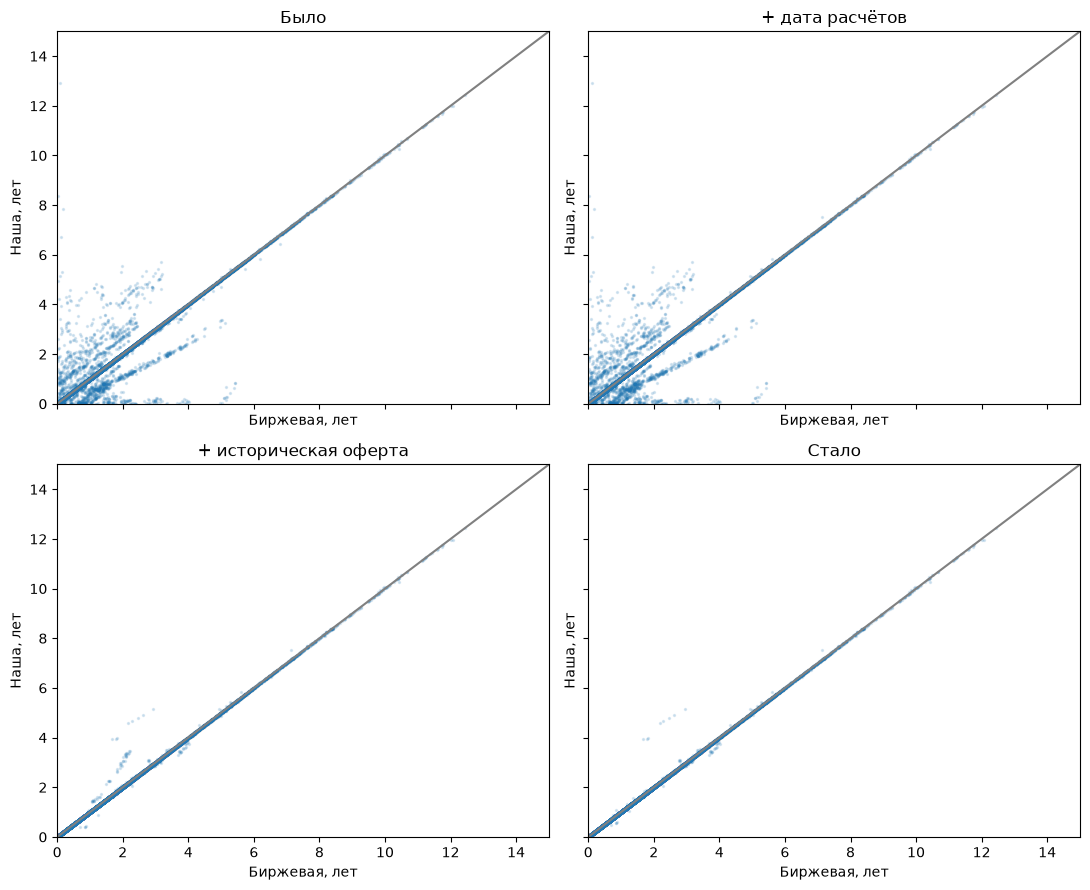

,SECID,TRADEDATE,settle_date,duration_moex,before,settlement,after
3628,SU26218RMFS6,2024-09-24,2024-09-25,4.317101,4.072190,4.318688,4.318687
3755,SU26218RMFS6,2025-03-25,2025-03-26,4.215878,3.996082,4.220269,4.220268


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
points = common.sample(min(30000, len(common)), random_state=42)
for ax, (key, title) in zip(axes.ravel(), steps.items()):
    ax.scatter(points["duration_moex"], points[key], s=2, alpha=0.15)
    ax.plot([0, 15], [0, 15], color="gray")
    ax.set(title=title, xlim=(0, 15), ylim=(0, 15), xlabel="Биржевая, лет", ylabel="Наша, лет")
plt.tight_layout()
plt.show()
examples = common[(common["SECID"] == "SU26218RMFS6") & common["TRADEDATE"].isin(
    pd.to_datetime(["2024-09-24", "2025-03-25"]))]
display(examples[["SECID", "TRADEDATE", "settle_date", "duration_moex", "before", "settlement", "after"]])


На одинаковых 566 561 строках доля совпадений дюрации с биржей в пределах 1% выросла с 76,31% до 97,68%. Учёт даты расчётов, исторической оферты и выплат уменьшает расхождения. Оставшиеся ошибки требуют отдельной проверки графика выплат.

## Проверка против биржи

Сравниваем только положительные дюрации. Отдельно считаем строки с нулевой/пустой
дюрацией биржи: деление на них создаёт бесконечные проценты.
Флоатеры и неподдерживаемые графики в долю совпадений не входят.
Относительная ошибка возле нуля нестабильна, поэтому рядом показываем ошибку в днях.

Строк для сверки: 566561 из 917912
Совпадает в пределах 1%: 97.68 %
Медианное расхождение, %: 0.062
Нет положительной дюрации биржи: 134149
                           rows  median_diff_pct  matched_pct
horizon_source currency                                      
buyback        CHF            5             0.00       100.00
               CNY         4751             0.09        98.72
               EUR          735             0.04        99.86
               RUB       203166             0.08        96.05
               USD         6557             0.07        99.74
maturity       CHF         1000             0.03       100.00
               CNY        10550             0.06        99.60
               EUR         3378             0.03       100.00
               RUB       298325             0.06        98.39
               USD        38094             0.04        99.51


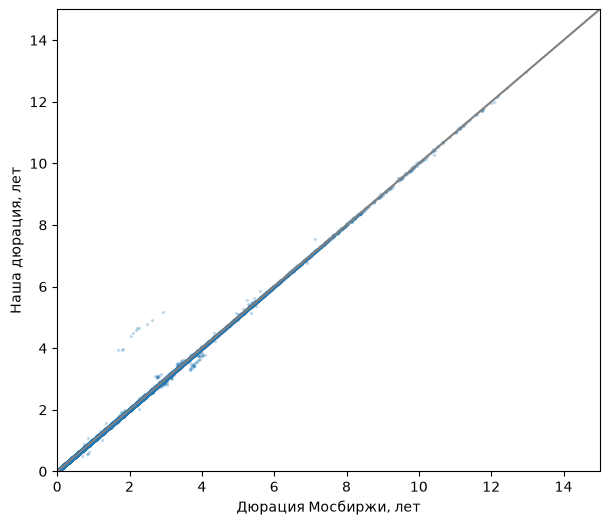

In [16]:
check = history.dropna(subset=["duration_calc", "duration_moex"]).copy()
check["diff_pct"] = (check["duration_calc"] / check["duration_moex"] - 1).abs() * 100
check["diff_days"] = (check["duration_calc"] - check["duration_moex"]).abs() * 365
print("Строк для сверки:", len(check), "из", len(history))
print("Совпадает в пределах 1%:", round(check["diff_pct"].lt(1).mean() * 100, 2), "%")
print("Медианное расхождение, %:", round(check["diff_pct"].median(), 3))
print("Нет положительной дюрации биржи:", int(history["duration_moex"].isna().sum()))
print(check.groupby(["horizon_source", "currency"]).agg(
    rows=("SECID", "size"), median_diff_pct=("diff_pct", "median"),
    matched_pct=("diff_pct", lambda x: x.lt(1).mean() * 100)).round(2))

plt.figure(figsize=(7, 6))
plot_data = check.sample(min(50000, len(check)), random_state=42)
plt.scatter(plot_data["duration_moex"], plot_data["duration_calc"], s=2, alpha=0.2)
plt.plot([0, 15], [0, 15], color="gray")
plt.xlim(0, 15)
plt.ylim(0, 15)
plt.xlabel("Дюрация Мосбиржи, лет")
plt.ylabel("Наша дюрация, лет")
plt.show()

In [17]:
sample = check[(check["SECID"] == "SU26218RMFS6") & check["TRADEDATE"].isin(
    pd.to_datetime(["2024-09-24", "2025-03-25"]))]
print(sample[["TRADEDATE", "settle_date", "duration_moex", "duration_calc", "diff_pct"]].to_string(index=False))

bad = check[check["diff_pct"] > 5]
print("Выпусков с хотя бы одним отклонением >5%:", bad["SECID"].nunique())
print(bad.groupby("SECID").agg(rows=("SECID", "size"), median_diff_pct=("diff_pct", "median"))
      .sort_values("median_diff_pct", ascending=False).head(10))

 TRADEDATE settle_date  duration_moex  duration_calc  diff_pct
2024-09-24  2024-09-25       4.317101       4.318687  0.036739
2025-03-25  2025-03-26       4.215878       4.220268  0.104143
Выпусков с хотя бы одним отклонением >5%: 240
              rows  median_diff_pct
SECID                              
RU000A105EV1    34       136.006683
RU000A1057B8   138       110.601254
RU000A0ZYKJ1     2        54.431908
RU000A1040S8     2        50.799236
RU000A0ZZQH9     3        35.235221
RU000A10E6U4     1        31.932596
RU000A102H34     3        27.530974
RU000A102G35     4        26.532148
RU000A102QL3    88        23.399303
RU000A101P27     2        20.025524


## Какие строки подходят для первого эксперимента по дюрации и выпуклости

Не удаляем сомнительные строки молча: сохраняем отдельную диагностику. Для первого
ML-эксперимента берём обычные бумаги с известными фиксированными купонами,
положительной биржевой дюрацией и расхождением не более 5%.

Это первичный фильтр качества, а не доказательство отсутствия утечки будущих данных.
Текущие справочник и график выплат - снимок на дату загрузки. Бумаги с не объявленными
на дату сделки купонами потребуют исторических снимков. Флоатеры, структурные бумаги,
ОФЗ-ИН и фиксированные купоны с неизвестными ставками в первый эксперимент не входят.
Несверенная выпуклость остаётся в диагностике; в `market_data` для неё будет пропуск.

In [18]:
history["duration_diff_pct"] = (history["duration_calc"] / history["duration_moex"] - 1).abs() * 100
history["validation_status"] = np.select(
    [history["coupon_type"].eq("floating"), history["duration_calc"].isna(),
     history["duration_moex"].isna(), history["duration_diff_pct"].gt(5)],
    ["approximation", "not_calculated", "no_reference", "mismatch"], default="matched")
details = history["SECID"].map(bond_info["COUPON_DETAILS"]).fillna("")
history["ml_eligible"] = (
    history["coupon_type"].isin(["fixed", "zero"])
    & ~history["is_structured"]
    & ~history["SECID"].str.startswith("SU52")
    & ~details.str.contains("неизвестными", case=False)
    & history["CLOSE"].notna() & history["YIELDCLOSE"].notna()
    & history["calc_status"].eq("ok")
    & history["duration_diff_pct"].le(5)
    & history["settlement_calendar_exact"]
)
print("Строк для первого ML-эксперимента:", int(history["ml_eligible"].sum()))

Строк для первого ML-эксперимента: 392902


## Сохраняем данные и диагностику отдельно

In [19]:
market_data = pd.DataFrame({
    "isin": history["SECID"].map(bond_info["ISIN"]),
    "trade_date": history["TRADEDATE"].dt.date,
    "source": "moex",
    "price_type": "trade",
    "price_clean": history["CLOSE"],
    "accrued_int": history["ACCINT"],
    "duration_mod": history["duration_mod"],

    "convexity": history["convexity"].where(history["validation_status"].isin(["matched", "approximation"])),
    "ytm": history["YIELDCLOSE"],
    "num_trades": history["NUMTRADES"],
})
if market_data["isin"].isna().any() or market_data.duplicated(["isin", "trade_date"]).any():
    raise ValueError("Пустой ISIN или дубли по ISIN и дате: экспорт остановлен")
market_data.to_parquet(DATA / "market_data.parquet", index=False)
bonds.to_parquet(DATA / "bonds.parquet", index=False)
diagnostic_cols = ["SECID", "TRADEDATE", "settle_date", "yield_date", "horizon_source", "coupon_type",
                   "currency", "duration_moex", "duration_calc", "duration_diff_pct", "calc_status",
                   "duration_source", "offer_price_assumed", "price_dirty_calc", "convexity",
                   "validation_status", "settlement_calendar_exact", "ml_eligible"]
history[diagnostic_cols].to_parquet(DATA / "calculation_diagnostics.parquet", index=False)
check.sort_values("diff_pct", ascending=False).head(1000).to_csv(DATA / "duration_mismatches.csv", index=False)
print("Сохранено строк market_data:", len(market_data))
print("Диагностика: calculation_diagnostics.parquet и duration_mismatches.csv")
market_data.head()

Сохранено строк market_data: 917912
Диагностика: calculation_diagnostics.parquet и duration_mismatches.csv


,isin,trade_date,source,price_type,price_clean,accrued_int,duration_mod,convexity,ytm,num_trades
0,RU000A10DQA8,2025-12-08,moex,trade,101.37,0.0000,5.567632,40.960540,6.88,327
1,RU000A10DQA8,2025-12-09,moex,trade,101.78,20.7903,5.576411,41.014223,6.81,227
2,RU000A10DQA8,2025-12-10,moex,trade,104.40,41.6026,5.600531,41.543087,6.35,175
3,RU000A10DQA8,2025-12-11,moex,trade,103.95,63.0453,5.604044,41.413902,6.43,163
4,RU000A10DQA8,2025-12-12,moex,trade,102.20,85.8020,5.570323,40.955850,6.73,106


## Признаки, доступные на дату наблюдения

Не используем DURATION, рассчитанную выпуклость, цены будущих купонов, SECID и название
эмитента в качестве признаков. Купонную ставку, валюту и номинал берём из строки
истории, а не из сегодняшнего справочника. Частоту купона восстанавливаем по
завершившемуся к дате оценки купонному периоду, без будущих сумм выплат.
Если тип купона не указан в исторической строке, признак будет `unknown_at_date`.
Текущая классификация используется только для ограничения исследуемой выборки.

Идентификатор эмитента нужен только для разделения выборок. Сектор и рейтинг
в загруженной истории отсутствуют: не подменяем их уровнем листинга.

In [20]:
issuer_file = DATA / "issuers.parquet"
if not issuer_file.exists() or REFRESH_REFERENCE:
    issuer_frames = []
    start = 0
    while True:
        frame = to_df(get("securities", {"engine": "stock", "market": "bonds", "is_trading": 1,
                                          "limit": 100, "start": start}), "securities")
        if frame.empty:
            break
        issuer_frames.append(frame)
        start += len(frame)
        if len(frame) < 100:
            break
    pd.concat(issuer_frames, ignore_index=True).to_parquet(issuer_file, index=False)
issuers = pd.read_parquet(issuer_file).drop_duplicates("secid").set_index("secid")
model_data = history[["SECID", "TRADEDATE", "settle_date", "yield_date", "FACEVALUE", "YIELDCLOSE",
                      "COUPONPERCENT", "COUPONVALUE", "CLOSE", "ACCINT", "coupon_type", "is_structured",
                      "ml_eligible", "settlement_calendar_exact", "duration_mod", "convexity",
                      "duration_source", "validation_status", "calc_status"]].copy()
model_data = model_data.rename(columns={"TRADEDATE": "trade_date", "FACEVALUE": "face_value", "YIELDCLOSE": "ytm",
                                        "COUPONPERCENT": "coupon_percent", "COUPONVALUE": "coupon_value",
                                        "CLOSE": "price_clean", "ACCINT": "accrued_int"})
model_data["isin"] = model_data["SECID"].map(bond_info["ISIN"])
model_data["issuer_id"] = model_data["SECID"].map(issuers["emitent_id"]).astype("Int64").astype("string")
model_data["issuer_name"] = model_data["SECID"].map(issuers["emitent_title"])
model_data["currency_asof"] = history["FACEUNIT"].replace({"SUR": "RUB"}).fillna("unknown_at_date")
model_data["years_to_maturity"] = (history["MATDATE"] - history["settle_date"]).dt.days / 365
model_data["years_to_yield_date"] = (history["yield_date"] - history["settle_date"]).dt.days / 365
model_data["has_buyback"] = history["BUYBACKDATE"].notna().astype(int)
model_data["is_government"] = history["SECID"].str.startswith("SU").astype(int)
raw_type = history["BONDTYPE"].fillna("")
raw_details = history["COUPON_DETAILS"].fillna("")
model_data["coupon_type_asof"] = np.select(
    [raw_type.str.contains("плавающ", case=False), raw_type.str.contains("Дисконтная", case=False),
     raw_type.str.contains("фиксированным", case=False) | raw_details.str.contains("Фиксированный")],
    ["floating", "zero", "fixed"], default="unknown_at_date")
model_data["coupon_period_days_asof"] = np.nan

In [21]:
for secid, group in history.groupby("SECID", sort=False):
    c = coupons[secid]
    if c.empty:
        continue
    dates = pd.to_datetime(c["coupondate"], format="%Y-%m-%d", errors="coerce")
    starts = pd.to_datetime(c["startdate"], format="%Y-%m-%d", errors="coerce")
    periods = pd.DataFrame({"end": dates, "days": (dates-starts).dt.days}).dropna().sort_values("end")
    if periods.empty:
        continue
    pos = np.searchsorted(periods["end"].to_numpy(), group["settle_date"].to_numpy(), side="right") - 1
    available = pos >= 0
    model_data.loc[group.index[available], "coupon_period_days_asof"] = periods["days"].to_numpy()[pos[available]]
model_data["coupon_freq_asof"] = (365 / model_data["coupon_period_days_asof"].where(
    model_data["coupon_period_days_asof"] > 0)).round()

model_data["convexity"] = model_data["convexity"].where(history["validation_status"].isin(["matched", "approximation"]))
model_data.to_parquet(DATA / "model_dataset.parquet", index=False)
print("Датасет для ТЗ:", model_data.shape)
print("Эмитент известен для", int(model_data["issuer_id"].notna().sum()), "строк")
display(model_data[["trade_date", "coupon_type_asof", "currency_asof", "coupon_percent", "coupon_freq_asof",
                    "years_to_yield_date", "duration_mod", "convexity"]].head())

Датасет для ТЗ: (917912, 30)
Эмитент известен для 917290 строк


,trade_date,coupon_type_asof,currency_asof,coupon_percent,coupon_freq_asof,years_to_yield_date,duration_mod,convexity
0,2025-12-08,fixed,CNY,7.0,NaN,7.482192,5.567632,40.960540
1,2025-12-09,fixed,CNY,7.0,NaN,7.479452,5.576411,41.014223
2,2025-12-10,fixed,CNY,7.0,NaN,7.476712,5.600531,41.543087
3,2025-12-11,fixed,CNY,7.0,NaN,7.473973,5.604044,41.413902
4,2025-12-12,fixed,CNY,7.0,NaN,7.465753,5.570323,40.955850
